In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
import seaborn as sns
from matplotlib.ticker import ScalarFormatter
import torch
from src.model import Model
from evaluation.utils import filter_sequences

# Define the global parameters
MAX_SEQ_LEN = 20000
MIN_SEQ_LEN = 2500
MIN_ABUNDANCE_VALUE = 10

# Set the style parameters
mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
# plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
# plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.serif"] = ["Computer Modern Roman"]
fontsize= 27
colors = ["tab:red", "tab:blue"]



In [3]:
datasets = ["reference", "plant", "marine"]
dataset_ids = [5, 6]
dataset2label = {
    "reference": r"\textsl{Reference}", "plant": r"\textsl{Plant}", "marine": r"\textsl{Marine}"
}

# Define the model path
model_path = os.path.join(os.getcwd(), "models", "k=4_d=256_negperpos=200_maxseq=100000_epoch=25_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_factortest.model")
# Load the model
kwargs, model_state_dict = torch.load(model_path, map_location=torch.device("cpu"))
model = Model(**kwargs)
model.load_state_dict(model_state_dict)

means, covs = dict(), dict()
for dataset in datasets:
    means[dataset], covs[dataset] = dict(), dict()

    for dataset_id in dataset_ids:

        # Define the data path
        data_path = os.path.join(
            os.getcwd(), "..", "..", "datasets", "dnaberts", "evaluation", dataset, f"binning_{dataset_id}.tsv"
        )

        # Filter the sequences based on the minimum length and abundance
        dna_sequences, labels_bin = filter_sequences(
            data_path=data_path, shorten=MAX_SEQ_LEN, min_len=MIN_SEQ_LEN, abundance=MIN_ABUNDANCE_VALUE,
        )

        # Get the DNA sequences
        with torch.no_grad():
            m, s = model.seq2emb(sequences=dna_sequences)
            means[dataset][dataset_id], covs[dataset][dataset_id] = m, s


+ After filtering, there are 37278 sequences from 323 classes.
+ After filtering, there are 28206 sequences from 249 classes.
+ After filtering, there are 71642 sequences from 181 classes.
+ After filtering, there are 68426 sequences from 196 classes.
+ After filtering, there are 119465 sequences from 515 classes.
+ After filtering, there are 125194 sequences from 527 classes.


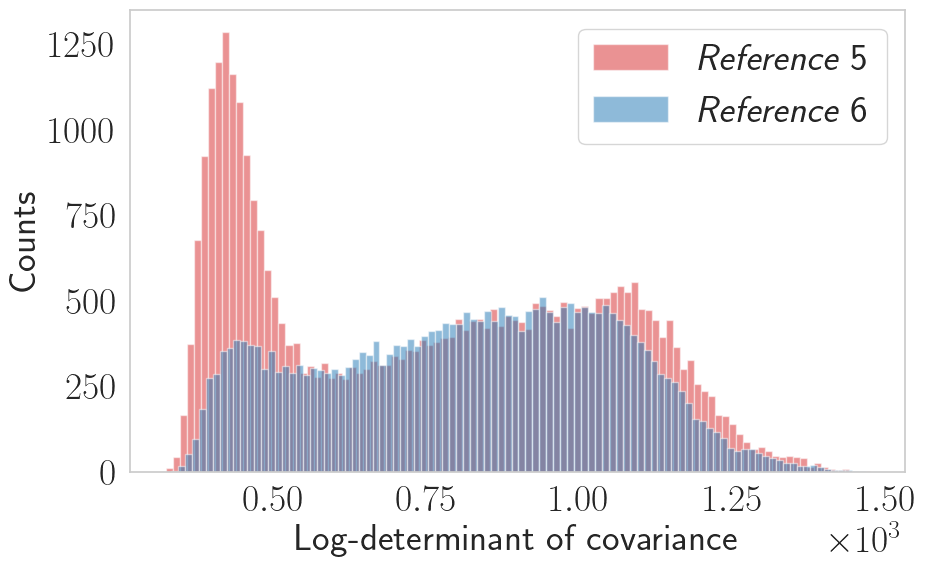

In [6]:
# Single plot
dataset = "reference"
plt.figure(figsize=(10, 6))
for j, dataset_id in enumerate(dataset_ids):
    values = np.log(covs[dataset][dataset_id] + 1).sum(axis=-1)
    plt.hist(values, color=colors[j], bins=100, alpha=0.5, label=f"{dataset2label[dataset]} {dataset_id}")
plt.xlabel('Log-determinant of covariance', fontsize=fontsize)
plt.ylabel('Counts', fontsize=fontsize)
plt.legend(fontsize=fontsize)
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
plt.gca().xaxis.get_offset_text().set_fontsize(fontsize)
plt.gca().yaxis.get_offset_text().set_fontsize(fontsize)
plt.gca().xaxis.set_major_formatter(formatter)
plt.grid(False)
plt.tick_params(axis='x', labelsize=fontsize)
plt.tick_params(axis='y', labelsize=fontsize)
plt.savefig(os.path.join(os.getcwd(), "figures", f"single_cov_distribution_{dataset}.png"), bbox_inches='tight')
# plt.show()

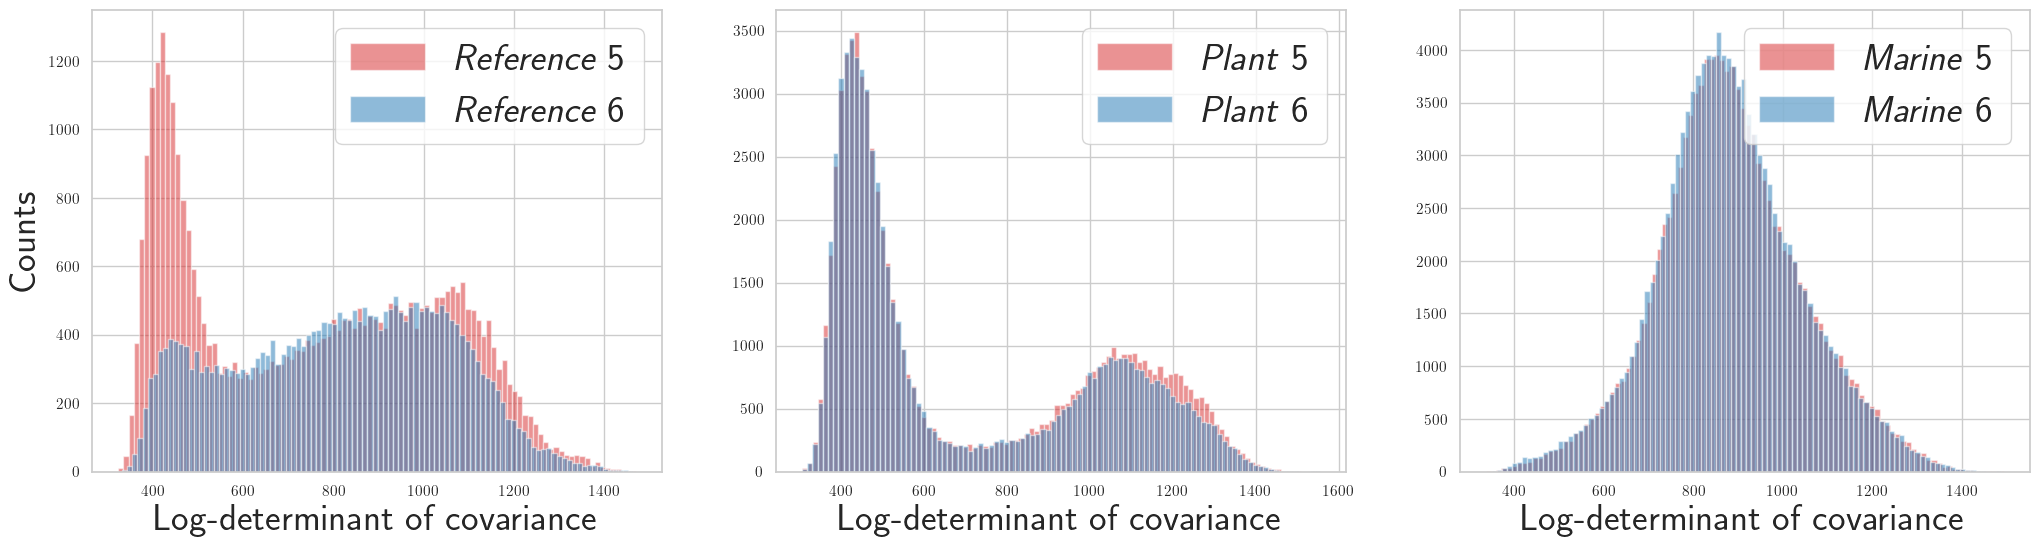

In [17]:
# Plot the histograms side by side
fig, axes = plt.subplots(1, 3, figsize=(25, 6))

for i, dataset in enumerate(datasets):
    for j, dataset_id in enumerate(dataset_ids):
        values = np.log(covs[dataset][dataset_id] + 1).sum(axis=-1)
        axes[i].hist(values, color=colors[j], bins=100, alpha=0.5, label=f"{dataset2label[dataset]} {dataset_id}")
    axes[i].set_xlabel('Log-determinant of covariance', fontsize=fontsize)
    # axes[i].set_xticks(axes[i].get_xticks(), axes[i].get_xticks(), fontsize=fontsize)
    if i == 0:
        axes[i].set_ylabel('Counts', fontsize=fontsize)
    axes[i].legend(fontsize=fontsize)
plt.savefig(os.path.join(os.getcwd(), "figures", f"all_cov_distribution.png"), bbox_inches='tight')
plt.show()